# 03 - Transactional Database Construction

Task 3 dari *PROJECT DATA MINING.pdf*. Input adalah `data/paper_author.parquet` hasil preprocessing Task 1. Item menggunakan `venue_id`, termasuk konferensi utama dan workshop (`*_workshops`), sesuai keputusan cakupan proyek. Trek pendamping sudah tergabung pada venue induknya.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display

from src import config
from src.transactions import AUTHOR_FILE, AUTHOR_YEAR_FILE, build_transactions
from src.viz import SERIES, apply_style, save

apply_style()
required = [AUTHOR_FILE, AUTHOR_YEAR_FILE, config.TABLES_DIR / "transaction_statistics.csv"]
required += [config.TABLES_DIR / f"{label}_transaction_{kind}.csv"
             for label in ("author", "author_year") for kind in ("examples", "length")]
if any(not path.exists() for path in required):
    build_transactions()

## 1. Definisi dan konstruksi

- **Author-Based**: kunci `author`; item adalah himpunan venue tempat penulis pernah menerbitkan makalah selama 2015-2025.
- **Author-Year-Based**: kunci `(author, year)`; item adalah himpunan venue penulis tersebut pada tahun yang bersangkutan.

Sumber `paper_author.parquet` sudah mencakup satu baris per pasangan makalah-penulis. Skrip `src/transactions.py` memilih kombinasi kunci dan venue yang unik, mengelompokkan venue, lalu menyimpan daftar item yang diurutkan. Penulis yang menerbitkan beberapa makalah pada venue yang sama dihitung satu kali dalam sebuah transaksi. Setiap transaksi memiliki minimal satu item.

In [2]:
for label, path in [("Author-Based", AUTHOR_FILE), ("Author-Year-Based", AUTHOR_YEAR_FILE)]:
    metadata = pq.ParquetFile(path)
    print(f"{label}: {metadata.metadata.num_rows:,} transaksi")
    print(metadata.schema_arrow)

Author-Based: 1,817,265 transaksi
author: string
venue_ids: list<element: string>
  child 0, element: string
n_items: int32
Author-Year-Based: 4,080,856 transaksi
author: string
year: int16
venue_ids: list<element: string>
  child 0, element: string
n_items: int32


## 2. Contoh transaksi

Sepuluh contoh untuk setiap representasi dipilih secara deterministik dengan hash kunci transaksi. `venue_ids` dipisahkan tanda `|` hanya pada tabel contoh; file Parquet menyimpannya sebagai list.

In [3]:
for label in ("author", "author_year"):
    print(f"10 contoh {label}")
    examples = pd.read_csv(config.TABLES_DIR / f"{label}_transaction_examples.csv")
    assert len(examples) == 10
    display(examples)

10 contoh author


,author,venue_ids,n_items
0,Emon Sarkar,apccas | iscas,2
1,Victor B. Suchkov,csae,1
2,Sanjeev Gunawardena,ifip11-10 | plans,2
3,Yesheng Gao,igarss,1
4,Subigya Nepal,chi | chil,2
5,Jinfan Yang,siggrapha,1
6,Lucas Steehouwer,apn,1
7,Richa Patel,amia,1
8,Francisco Barrio,teem,1
9,Aurélien Bour,isspit,1


10 contoh author_year


,author,year,venue_ids,n_items
0,Dimitrios Gunopulos,2016,asunam | birthday | coling | dais | gis | hcom...,10
1,Peihe Yan,2023,iccns,1
2,Florian Levet,2024,biostec,1
3,Qiaoduo Chen,2022,icbde,1
4,Miércio Cardoso De Alcântara Neto,2020,ssn,1
5,Milla Sherman,2025,aied,1
6,S. Shahnawazuddin,2019,ncc,1
7,Juan David Perez,2020,isbi,1
8,Luiz C. Gomes-Jr,2018,eurosys_workshops,1
9,Jef Vandemeulebroucke,2018,miccai_workshops,1


## 3. Jumlah transaksi, item unik, dan panjang transaksi

`n_items` adalah jumlah venue unik dalam satu transaksi. Distribusi lengkap tersedia pada `results/tables/author_transaction_length.csv` dan `author_year_transaction_length.csv`. Jumlah kemunculan item dapat melampaui jumlah pasangan penulis-venue unik pada representasi tahunan, karena venue yang sama dapat muncul kembali untuk penulis yang sama pada tahun lain.

In [4]:
stats = pd.read_csv(config.TABLES_DIR / "transaction_statistics.csv")
stats["pct_single_item"] = (100 * stats["n_single_item"] / stats["n_transactions"]).round(2)
display(stats)

,representation,n_transactions,n_item_occurrences,n_single_item,mean_items,median_items,max_items,n_unique_items,pct_single_item
0,author,1817265,4918319,1057806,2.706,1.0,337,4876,58.21
1,author_year,4080856,6531671,2891570,1.601,1.0,86,4876,70.86


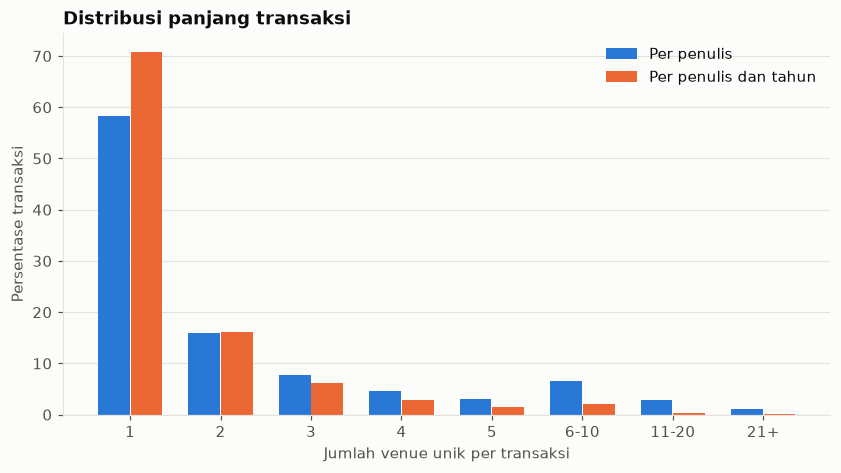

In [5]:
bins = [(1, 1, "1"), (2, 2, "2"), (3, 3, "3"), (4, 4, "4"),
        (5, 5, "5"), (6, 10, "6-10"), (11, 20, "11-20"), (21, float("inf"), "21+")]
fig, ax = plt.subplots(figsize=(9, 4.5))
for label, legend, color in [("author", "Per penulis", SERIES[0]),
                              ("author_year", "Per penulis dan tahun", SERIES[1])]:
    dist = pd.read_csv(config.TABLES_DIR / f"{label}_transaction_length.csv")
    total = dist["n_transactions"].sum()
    values = [100 * dist.loc[dist["n_items"].between(lo, hi), "n_transactions"].sum() / total
              for lo, hi, _ in bins]
    offsets = [-0.18, 0.18]
    x = [i + offsets[0 if label == "author" else 1] for i in range(len(bins))]
    ax.bar(x, values, width=0.35, label=legend, color=color)
ax.set_xticks(range(len(bins)), [name for _, _, name in bins])
ax.set_xlabel("Jumlah venue unik per transaksi")
ax.set_ylabel("Persentase transaksi")
ax.set_title("Distribusi panjang transaksi")
ax.legend()
ax.grid(axis="x", visible=False)
save(fig, "03_transaction_lengths")
plt.show()

## 4. Perbandingan dan implikasi untuk Frequent Pattern Mining

**Author-Based** memuat 1.817.265 transaksi dengan rata-rata 2,706 item; 58,21% hanya memiliki satu item. Representasi ini menangkap hubungan konferensi dan workshop sepanjang karier penulis pada periode pengamatan. Pasangan venue yang terpisah bertahun-tahun tetap dianggap muncul bersama, sehingga hasilnya tidak menyatakan kedekatan waktu.

**Author-Year-Based** memuat 4.080.856 transaksi dengan rata-rata 1,601 item; 70,86% hanya memiliki satu item. Representasi ini lebih tepat untuk pola publikasi dalam satu tahun dan dapat dipakai untuk analisis per periode. Ia memecah riwayat penulis menjadi beberapa transaksi, sehingga pola lintas tahun tidak terlihat. Penulis yang aktif pada banyak tahun menyumbang lebih dari satu transaksi.

Kedua representasi memiliki **4.876 item unik**. Untuk mining, panjang transaksi yang lebih besar pada Author-Based membuka lebih banyak kombinasi item; transaksi tahunan lebih pendek dan biasanya menghasilkan lebih sedikit kombinasi per transaksi. Support harus selalu dibagi dengan jumlah transaksi representasi yang sedang dianalisis. Task 4 dalam PDF secara khusus memakai Author-Based, sedangkan analisis temporal memakai Author-Year-Based.